# 01 — Exploração dos datasets reais

**PlantVillage** (laboratório, Mohanty et al. 2016) e **PlantDoc** (campo, Singh et al. 2020), restritos às 6 classes do PlantAI; mais o corpus textual de sintomas e o de perguntas.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
from src.ml import dataset as ds
pv = ds.list_records(ds.PLANTVILLAGE_DIR); pdoc = ds.list_records(ds.PLANTDOC_DIR, use_leaf_groups=False)
df = pd.DataFrame({'PlantVillage': pd.Series([r.label for r in pv]).value_counts(), 'PlantDoc': pd.Series([r.label for r in pdoc]).value_counts()}).fillna(0).astype(int)
display(df); print('Total PlantVillage:', len(pv), '| Total PlantDoc:', len(pdoc))

,PlantVillage,PlantDoc
Corn_(maize)___Common_rust_,1192,116
Potato___Early_blight,1000,117
Potato___Late_blight,1000,105
Tomato___Early_blight,1000,88
Tomato___Late_blight,1909,111
Tomato___healthy,1591,63


Total PlantVillage: 7692 | Total PlantDoc: 600


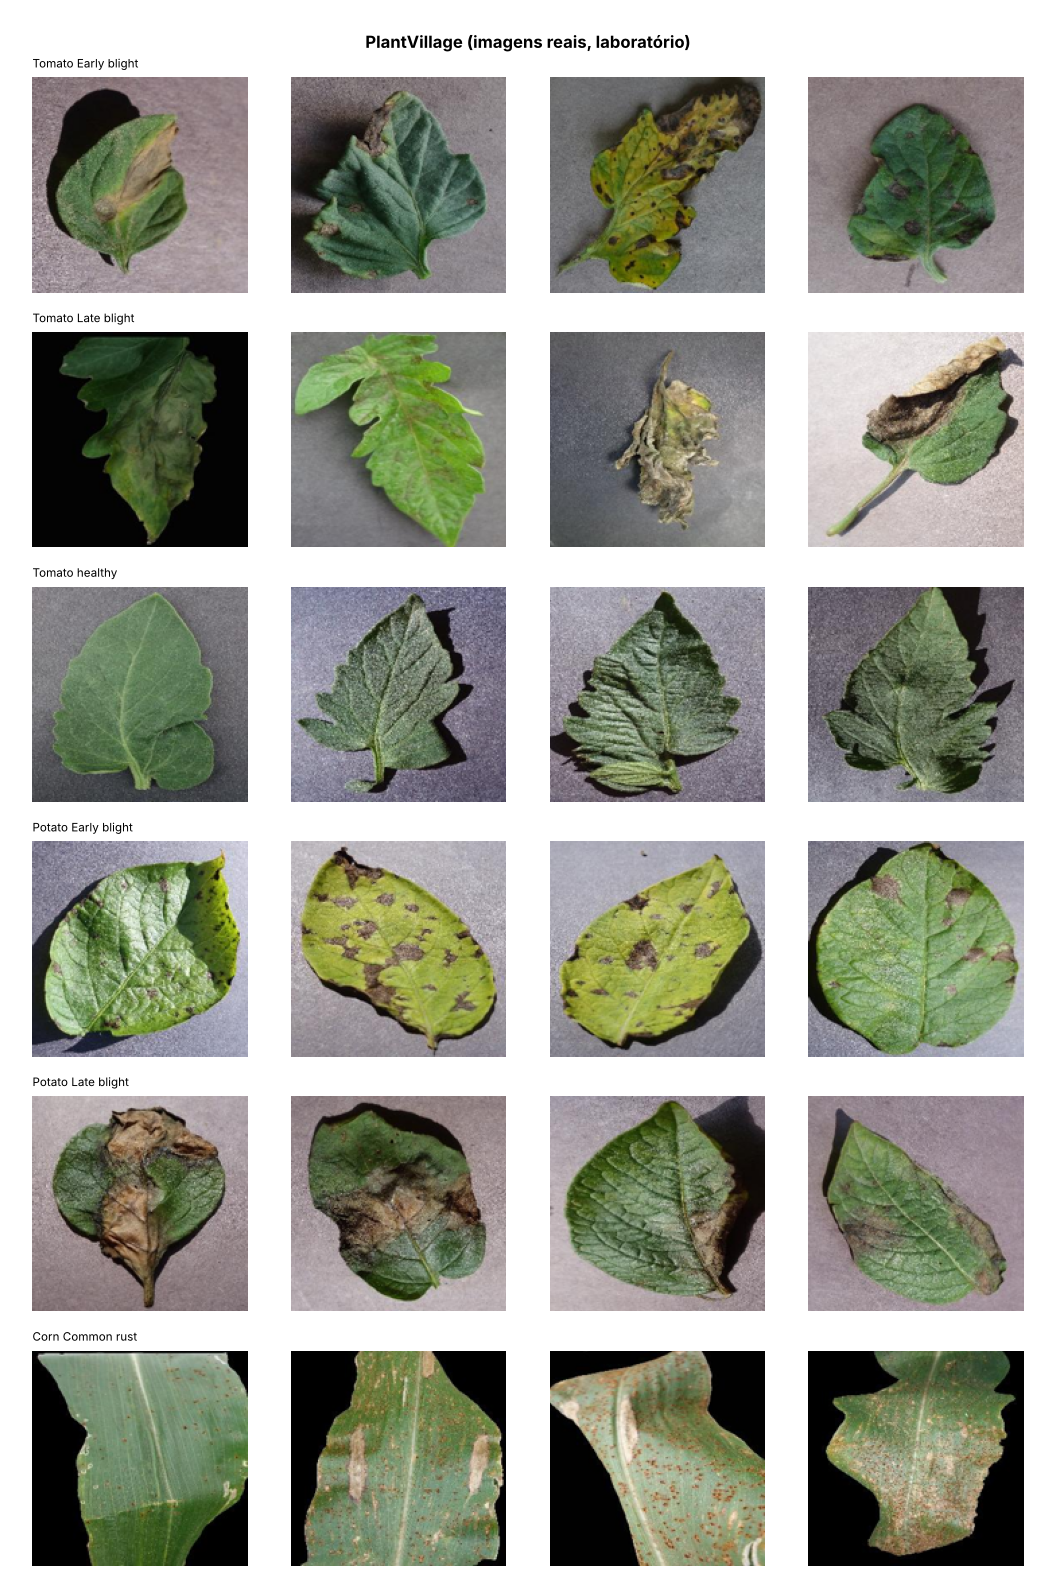

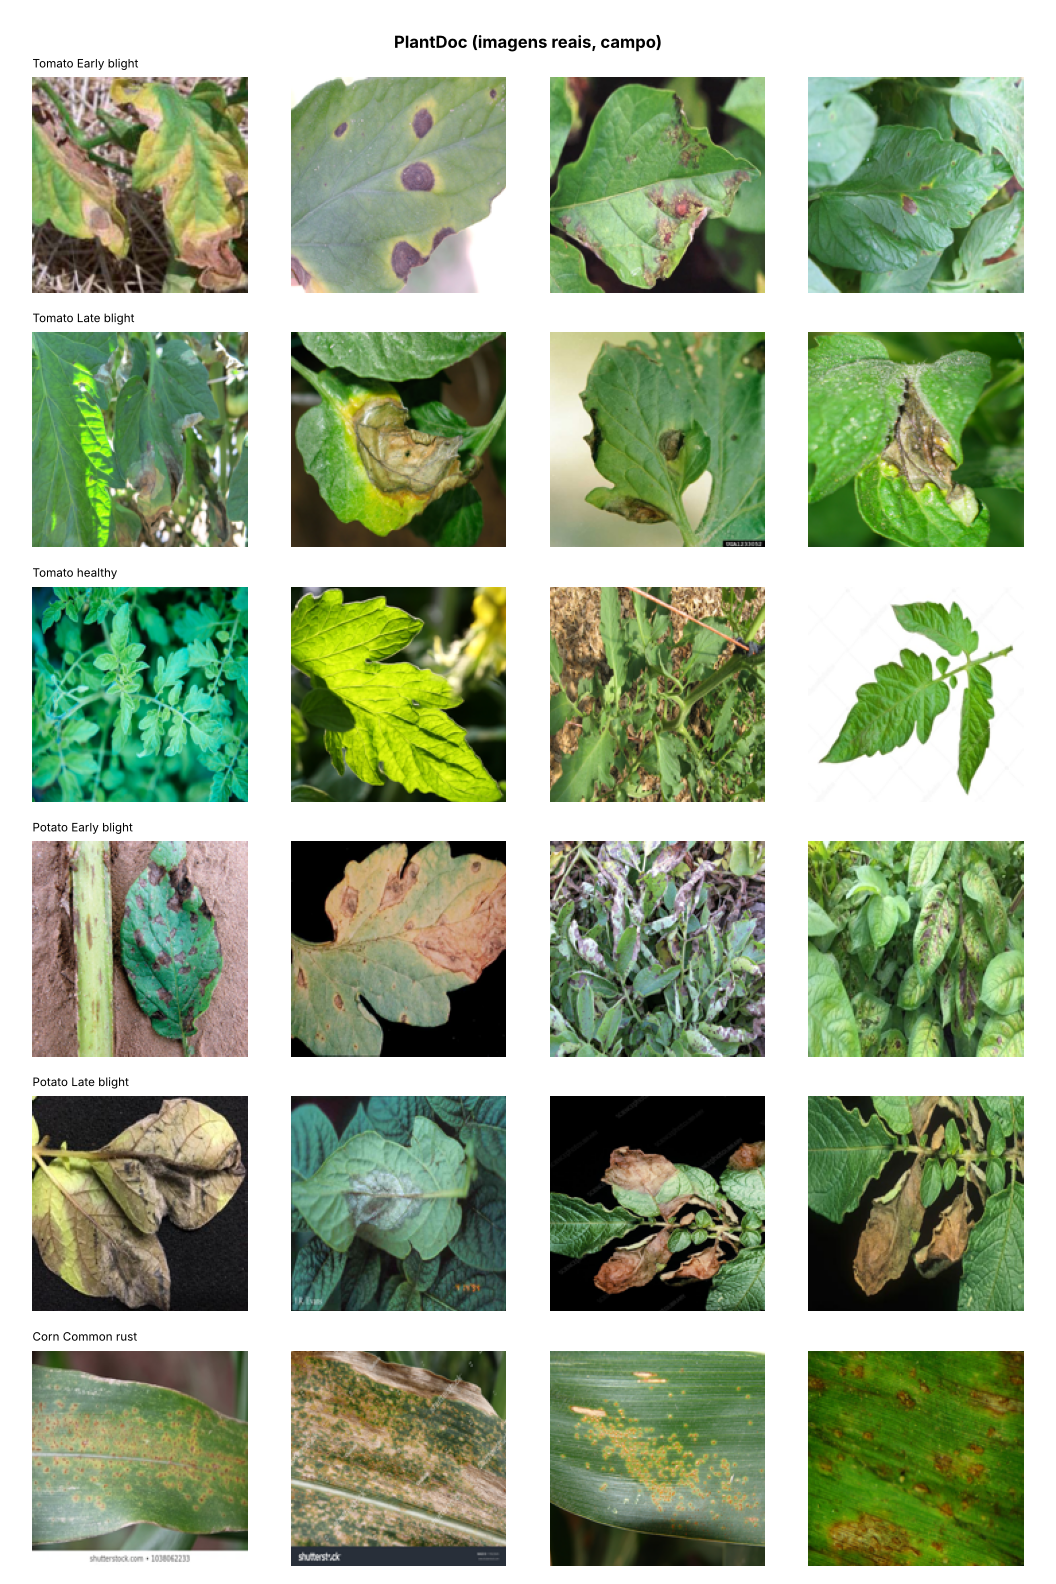

In [3]:
show('plots/leaf_samples_plantvillage.png'); show('plots/leaf_samples_plantdoc.png')

In [4]:
sym = pd.read_csv(ROOT / 'data' / 'symptoms_sample.csv'); q = pd.read_csv(ROOT / 'data' / 'question_intents.csv')
print('Textos de sintomas:', len(sym), '| perguntas:', len(q))
display(sym.groupby(['crop','disease_class']).size().rename('textos').reset_index())
display(sym.sample(6, random_state=1)[['disease_class','symptom_description']])

Textos de sintomas: 180 | perguntas: 150


,crop,disease_class,textos
0,Batata,Potato___Early_blight,30
1,Batata,Potato___Late_blight,30
2,Milho,Corn_(maize)___Common_rust_,30
3,Tomate,Tomato___Early_blight,30
4,Tomate,Tomato___Late_blight,30
5,Tomate,Tomato___healthy,30


,disease_class,symptom_description
116,Tomato___healthy,"Folhas de tomate limpas, firmes e de cor verde..."
112,Tomato___healthy,"folhas de tomate sem manchas e sem amarelar, p..."
99,Tomato___Late_blight,Folhas e hastes com lesões encharcadas escuras...
161,Corn_(maize)___Common_rust_,Milho com folhas salpicadas de bolinhas cor de...
35,Potato___Early_blight,Batateira com placas necróticas marrons em for...
54,Corn_(maize)___Common_rust_,Sintomas de ferrugem no milharal: pústulas elí...
